#ДЗ Поворин Георгий :)

## Задание 1

###Продуктовая гипотеза
**Цепочка «изменение $\rightarrow$ механизм $\rightarrow$ целевая метрика»:**  
Показ блока «Похожие вакансии» (3–5 вакансий с возможностью откликнуться в 1 клик) сразу после отклика на вакансию $\rightarrow$ соискатель сразу видит релевантные альтернативы и совершает дополнительные отклики без возврата к поиску $\rightarrow$ растёт среднее число релевантных откликов на соискателя (`relevant_responses_app`).

### Классификация метрик и параметры критериев

| Корзина | Метрика | Тип теста | Уровень $\alpha$ | Роль и порог решения |
|---|---|---|---|---|
| **Целевая** | `relevant_responses_app` на соискателя | Двусторонний | `0.05` | Главная метрика решения. Фича окупается при росте минимум на **+1.7%** |
| **Guardrail** | `invitations_app` на соискателя | Односторонний (на снижение) | `0.05` | Защитная метрика. Если приглашения упадут более чем на **3%**, фичу не раскатываем |
| **Информационные** | `responses_app` на соискателя;<br>`vacancy_views_app` на соискателя;<br>доля откликов из блока «Похожие вакансии» | Двусторонний | `0.001` | Объясняют механику (выросло ли общее число откликов, не упали ли просмотры в выдаче, кликают ли в сам блок). Строгий $\alpha = 0.001$ защищает от шума |



### Единица рандомизации, популяция и trigger event
* **Единица рандомизации:** `user_id` соискателя (`user_type == 'APPLICANT'`). Сплитуем именно пользователей, а не отдельные отклики или сеансы, так как иначе один человек при разных откликах будет попадать то в контроль, то в тест,а его опыт смешается, и наблюдения перестанут быть независимыми
* **Trigger event:** момент первого отклика соискателя на вакансию в период эксперимента (поскольку по условию блок виден только после отклика)
* **Анализируемая популяция:** соискатели (`user_type == 'APPLICANT'`), дошедшие до trigger event то есть совершившие хотя бы один отклик за время эксперимента (`responses_app > 0`). Исключение пользователей без откликов убирает из выборки тех, кто физически не мог увидеть фичу, снижает дисперсию и повышает чувствительность тестаа

In [14]:
from pathlib import Path
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt

## Задание 2



In [15]:
plt.rcParams["figure.figsize"] = (10, 4)

data_dir = Path("data")
users = pd.read_csv(data_dir / "users.csv")
metrics = pd.read_csv(data_dir / "user_week_metrics.csv")

print("users:", users.shape, "| дубли user_id:", users["user_id"].duplicated().sum())
print("metrics:", metrics.shape, "| дубли (week_start, user_id):", metrics.duplicated(["week_start", "user_id"]).sum())

#оставляем только соискателей
apps_u = users[users["user_type"] == "APPLICANT"].copy()
apps = metrics[metrics["user_type"] == "APPLICANT"].copy()

cols = ["vacancy_views_app", "responses_app", "relevant_responses_app", "invitations_app"]
print("Пропуски у соискателей (metrics):", apps[cols].isna().sum().to_dict())
print("Пропуски у соискателей (users):", apps_u[["reg_date", "region_group", "platform"]].isna().sum().to_dict())
print("Несостыковки с users:", (~apps["user_id"].isin(apps_u["user_id"])).sum())
print("Нарушения логики (inv > rel или rel > resp):",
      ((apps["invitations_app"] > apps["relevant_responses_app"]) |
       (apps["relevant_responses_app"] > apps["responses_app"])).sum())

#сводка по неделям (опять же для соискателей)
weekly = apps.groupby("week_start", as_index=False).agg(
    active_users=("user_id", "nunique"),
    triggered_users=("responses_app", lambda s: (s > 0).sum()),
    rel_mean=("relevant_responses_app", "mean"),
    rel_std=("relevant_responses_app", "std"),
    inv_mean=("invitations_app", "mean"),
    inv_std=("invitations_app", "std"),
)
display(weekly)

users: (388000, 6) | дубли user_id: 0
metrics: (870685, 10) | дубли (week_start, user_id): 0
Пропуски у соискателей (metrics): {'vacancy_views_app': 0, 'responses_app': 0, 'relevant_responses_app': 0, 'invitations_app': 0}
Пропуски у соискателей (users): {'reg_date': 0, 'region_group': 0, 'platform': 0}
Несостыковки с users: 0
Нарушения логики (inv > rel или rel > resp): 0


,week_start,active_users,triggered_users,rel_mean,rel_std,inv_mean,inv_std
0,2026-03-09,102701,94675,2.690568,3.134650,0.330435,0.835008
1,2026-03-16,103872,95857,2.669950,2.988372,0.328828,0.808137
2,2026-03-23,103090,95082,2.701717,2.990464,0.332030,0.804263
3,2026-03-30,101859,93844,2.695128,3.106595,0.330977,0.820631
4,2026-04-06,102791,94868,2.691559,3.099284,0.331478,0.828771
5,2026-04-13,103926,95994,2.723255,3.086843,0.332641,0.819586
6,2026-04-20,102599,94635,2.681030,3.049104,0.328736,0.817270
7,2026-04-27,53178,34259,2.667250,6.334765,0.337640,1.233338
8,2026-05-04,49522,31660,2.575986,6.118831,0.322443,1.155463


дублей и пропусков не обнаружил, вроде бычистые данные

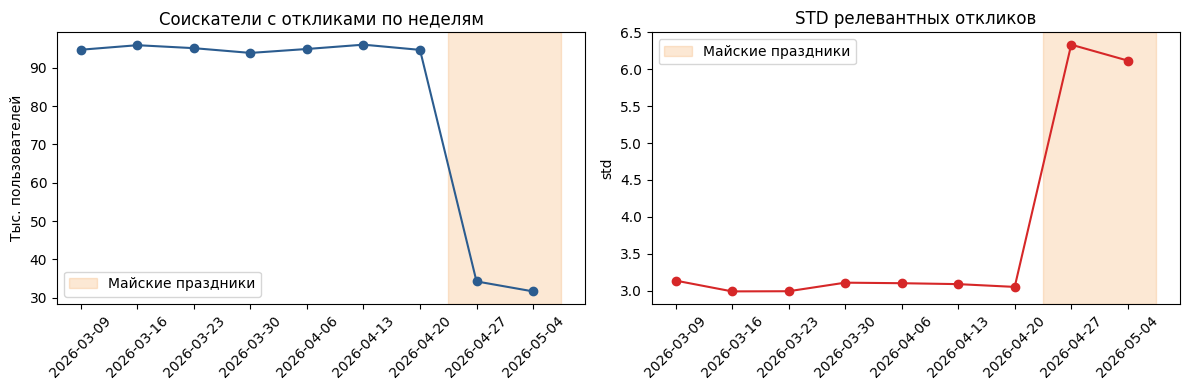

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(weekly["week_start"], weekly["triggered_users"] / 1000, marker="o", color="#2B5C8F")
axes[0].axvspan(6.5, 8.5, color="#F28E2B", alpha=0.2, label="Майские праздники")
axes[0].set_title("Соискатели с откликами по неделям")
axes[0].set_ylabel("Тыс. пользователей")
axes[0].tick_params(axis="x", rotation=45)
axes[0].legend()

axes[1].plot(weekly["week_start"], weekly["rel_std"], marker="o", color="#D62728")
axes[1].axvspan(6.5, 8.5, color="#F28E2B", alpha=0.2, label="Майские праздники")
axes[1].set_title("STD релевантных откликов")
axes[1].set_ylabel("std")
axes[1].tick_params(axis="x", rotation=45)
axes[1].legend()

plt.tight_layout()
plt.show()

###Выбор периода для нашего прогноза:
первые 7 недель (`2026-03-09` – `2026-04-20`)выглядят стабильными ( около 95 тыс. откликающихся соискателей в неделю, std метрики ~3.0–3.1). На 8-й и 9-й неделях начинаются майские праздники: аудитория падает почти вдвое (до ~34 и ~31.7 тыс.), а разброс целевой метрики удваивается (Std вырастает до ~6.3). Значит для расчёта базовой сетки MDE на 1–5 недель берём 5 чистых недель перед майскими праздниками (`2026-03-23` – `2026-04-20`)



###Расчёт MDE для тестов длительностью 1–5 недель

* **Определение метрики и популяции:** для окна в k недель суммируем показатели каждого соискателя (графа `APPLICANT`) за эти k недель и включаем в расчёт тех, кто совершил хотя бы 1 отклик (`responses_app > 0`). Размер одной группы при сплите 50/50: n = N / 2.
* **Формулы MDE (мощность $1 - \beta = 80\%$, $z_{0.8} \approx 0.84$):**
  * для целевой метрики (двусторонний тест, $\alpha = 0.05$, $z_{0.975} \approx 1.96$): $\Delta = (z_{0.975} + z_{0.8}) \cdot \sigma \sqrt{2/n}$, $\text{MDE}_{\text{цел}}, \% = \frac{\Delta}{\bar{Y}} \cdot 100\%$
  * для guardrail-метрики (односторонний тест, $\alpha = 0.05$, $z_{0.95} \approx 1.645$): $\Delta = (z_{0.95} + z_{0.8}) \cdot \sigma \sqrt{2/n}$, $\text{MDE}_{\text{guard}}, \% = \frac{\Delta}{\bar{Y}} \cdot 100\%$

In [19]:
weeks = sorted(apps["week_start"].unique())
clean_weeks = weeks[2:7]

# двусторонний alpha = 0.05 (около 1.96)
z_a2 = stats.norm.ppf(1 - 0.05 / 2)
#одност-й alpha = 0.05 (около 1.645)
z_a1 = stats.norm.ppf(1 - 0.05)
#мощность 80% (около 0.84)
z_b = stats.norm.ppf(0.80)

rows = []
for k in range(1, 6):
    sub = apps[apps["week_start"].isin(clean_weeks[:k])]
    user_df = sub.groupby("user_id", as_index=False)[cols].sum()
    pop = user_df[user_df["responses_app"] > 0]  # популяция с trigger event

    n_grp = len(pop) / 2

    #Цель.метрика - релевантные отклики
    m_rel = pop["relevant_responses_app"].mean()
    s_rel = pop["relevant_responses_app"].std(ddof=1)
    mde_rel = (z_a2 + z_b) * s_rel * np.sqrt(2 / n_grp) / m_rel * 100

    # Guardrail-метрика- приглашения
    m_inv = pop["invitations_app"].mean()
    s_inv = pop["invitations_app"].std(ddof=1)
    mde_inv = (z_a1 + z_b) * s_inv * np.sqrt(2 / n_grp) / m_inv * 100

    rows.append({
        "недель": k,
        "соискателей_всего": len(pop),
        "на_группу": int(n_grp),
        "среднее_рел_откл": round(m_rel, 3),
        "std_рел_откл": round(s_rel, 3),
        "MDE_целевая_%": round(mde_rel, 2),
        "среднее_пригл": round(m_inv, 3),
        "std_пригл": round(s_inv, 3),
        "MDE_guardrail_%": round(mde_inv, 2),
    })

mde_df = pd.DataFrame(rows)
display(mde_df)

,недель,соискателей_всего,на_группу,среднее_рел_откл,std_рел_откл,MDE_целевая_%,среднее_пригл,std_пригл,MDE_guardrail_%
0,1,95082,47541,2.929,3.005,1.86,0.360,0.831,3.72
1,2,155021,77510,3.568,4.191,1.67,0.438,1.049,3.02
2,3,197120,98560,4.209,5.366,1.61,0.518,1.281,2.77
3,4,228352,114176,4.873,6.500,1.56,0.598,1.501,2.61
4,5,251364,125682,5.521,7.607,1.54,0.678,1.725,2.53


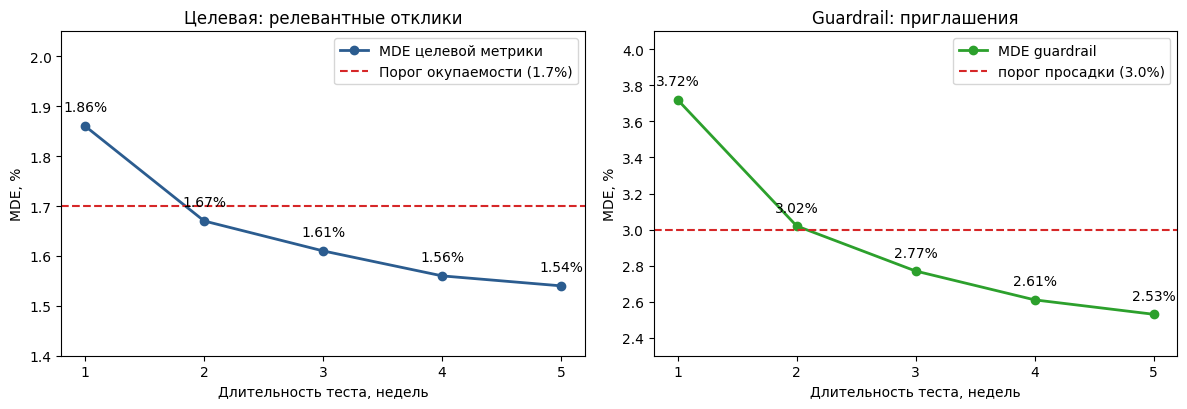

In [23]:
#зависимотсь MDE от длительности эксперимента
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
#a=0.05

#MDE = 1.7 так как по условию фича будет окупаться при росте рел.откликов на мин. 1.7%, ниже MDE не имеет брать смысла
axes[0].plot(mde_df["недель"], mde_df["MDE_целевая_%"], marker="o", lw=2, color="#2B5C8F", label="MDE целевой метрики")
axes[0].axhline(1.7, color="#D62728", ls="--", label="Порог окупаемости (1.7%)")
for _, r in mde_df.iterrows():
    axes[0].annotate(f"{r['MDE_целевая_%']:.2f}%", (r["недель"], r["MDE_целевая_%"] + 0.03), ha="center")
axes[0].set_title("Целевая: релевантные отклики")
axes[0].set_xlabel("Длительность теста, недель")
axes[0].set_ylabel("MDE, %")
axes[0].set_xticks(range(1, 6))
axes[0].set_ylim(1.4, 2.05)
axes[0].legend()


#тут похожая ситуация, не помню описывал ли это выше, но берем MDE=3, потому что при падении больше чем на 3%
#фичу не запускаем(а также тут односторонний тест, так как нас интересует лишь падение)
axes[1].plot(mde_df["недель"], mde_df["MDE_guardrail_%"], marker="o", lw=2, color="#2CA02C", label="MDE guardrail")
axes[1].axhline(3.0, color="#D62728", ls="--", label="порог просадки (3.0%)")
for _, r in mde_df.iterrows():
    axes[1].annotate(f"{r['MDE_guardrail_%']:.2f}%", (r["недель"], r["MDE_guardrail_%"] + 0.08), ha="center")
axes[1].set_title("Guardrail: приглашения")
axes[1].set_xlabel("Длительность теста, недель")
axes[1].set_ylabel("MDE, %")
axes[1].set_xticks(range(1, 6))
axes[1].set_ylim(2.3, 4.1)
axes[1].legend()

plt.tight_layout()
plt.show()

###Объяснение для графика
1. **Быстрое снижение на 1–3 неделях:** на старте активно приходят новые соискатели, поэтому std уменьшается как $1/\sqrt{n}$, а MDE в свою очередь заметно падает
2. **Выход на плато на 4–5 неделях:** прирост новых уникальных пользователей замедляется (постоянная аудитория возвращается из недели в неделю, и база растёт уже медленно), а std накопленной метрики $\sigma$ растёт пропорционально длине окна (объясняется это тем, чт активные кандидаты копят много откликов, усиливается разброс) Рост разброса $\sigma$ почти компенсирует рост $\sqrt{n}$, поэтому кривая выравнивается(1.61-1.56-1.54)

Также стоит заметить, что если бы окно затронуло майские праздники, кривая и вовсе улетела бы вверх из-за провала трафика и скачка дисперсии

## Задание 3
**Выбранный срок:** **3 недели — с понедельника 5 апреля по воскресенье 25 апреля 2027 года**

### Обоснование
1. **Соответствие бизнес-порогам:**
   * за **1 неделю** $\text{MDE}_{\text{цел}} = 1.86\%$ (> 1.7%) и $\text{MDE}_{\text{guardrail}} = 3.73\%$ (> 3.0%) — мощности не хватает ни по одной метрике
   * за **2 недели** $\text{MDE}_{\text{цел}} = 1.67\%$ (впритык к порогу 1.7%), а $\text{MDE}_{\text{guardrail}} = 3.02\%$, всё ещё чуть выше допустимой просадки в 3.0%;
   * на **3-й неделе** $\text{MDE}_{\text{цел}} = 1.61\% < 1.7\%$ и $\text{MDE}_{\text{guardrail}} = 2.77\% < 3.0\%$ — оба бизнес-ограничения выполняются
   * держать тест на 4–5 неделях почти не снижает MDE,выигрыш всего несколько сотых
2. **Недельные циклы:** 21 день — ровно 3 полные недели, поэтому соотношение будних и выходных дней в контроле и тесте идентично (в теории мы могли бы взять меньше дней, так как у MDE есть небольшой запас, но я предпочту 3 ровные недели для стабильности)
3. **Календарь и майские праздники:** тест стартанет 5 апреля 2027 года и завершится **25 апреля 2027 года** - ровно за неделю до майских праздников, мы полностью избегаем праздничных выбросов и искажений

### Сообщение продакту
> «Запускаем эксперимент в понедельник 5 апреля 2027 года ровно на **3 недели** (до 25 апреля), делим соискателей пополам.
За этот срок наберём около **197 тыс. откликающихся соискателей** (примерно 98.5 тыс. в каждой группе) и успеем остановить тест до майских праздников. С вероятностью 80% мы гарантированно заметим рост релевантных откликов от **+1.61%** (это ниже порога +1.7%, то есть окупаемый эффект мы не упустим), и еще поймаем падение приглашений, если оно превысит **-2.77%** (тоже строже нашего стоп-порога в -3%)»

### Вопросик
на всякий случай разжевал информацию для продакта, подскажите, в реальной работе по большей части правда нужно так делать? мне казалось продакты хоть и имеют другую направленность, но должны примерно понимать хотя бы базу MDE

## Задание 4. Риски эксперимента

1. **Пересечения с другими экспериментами:**  
   Перед запуском обязательно проверим список предстоящих тестов: на экране после отклика, в карточке вакансии и в алгоритмах рекомендаций/ранжирования и тп не должно идти параллельных экспериментов, дабы не сместить оценку эффекта и не затруднить (а может и чуток сломать) наш дальнейший анализ и оценку
2. **Праздники и сезонность:**  
   Майские праздники (1–3 и 8–10 мая) резко снижают активность соискателей и работодателей и вдвое увеличивают дисперсию метрик(см. график выше) Остановка теста 25 апреля полностью устраняет этот риск; в случае задержки релиза запуск нельзя сдвигат впритык к майским праздникам, так как каждый год их эффект может начаться чуть заранее
3. **Мониторинг во время теста и условия остановки:**  
   * **Технические чеки:** проверка SRM критерием $\chi^2$ (при $p < 0.001$ сразу останавливаем тест и ищем баг), контроль прогрузки данных по дням и защита от экстремальных багов (к прмиеру, жесткое падение приглашений или дублирования откликов и тп)
   * **Запрет на подглядывание:** не останавливаем эксперимент раньше 25 апреля при случайном $p < 0.05$ (в противном случае вероятность ложного прокраса вырастает) и не продлеваем его на 4-ю неделю
4. **Срезы и множественные сравнения:**  
   После завершения теста посмотрим эффект по признакам пользователей из `users.csv`: платформа (`app`, `desktop`, `mobile_web` — 3 группы), группа регионов (`Москва и СПб`, `Города-миллионники`, `Остальные` — 3 группы) и стаж с даты регистрации `reg_date` (новички vs опытные — 2 группы). Итого получимс 8 проверок: без поправки шанс хотя бы одной ложной находки был бы $\text{FWER} = 1 - 0.95^8 \approx 33.7\%$. Поэтому применяем **поправку Холма** (она будет помощнее Бонферрони), а найденные сегментные эффекты оформляем как гипотезы для следующих тестов

## Задание 5. А/А-тест на исторических данных

In [24]:
#возьмем 3 чистые апрельские недели
aa_weeks = ["2026-04-06", "2026-04-13", "2026-04-20"]
aa_df = (
    apps[apps["week_start"].isin(aa_weeks)]
    .groupby("user_id", as_index=False)[cols]
    .sum()
)
aa_pop = aa_df[aa_df["responses_app"] > 0].reset_index(drop=True)

y = aa_pop["relevant_responses_app"].to_numpy()
n_total = len(y)

rng = np.random.default_rng(42)
n_sims = 1000
p_values = np.empty(n_sims)

for i in range(n_sims):
    in_test = rng.random(n_total) < 0.5
    _, p = stats.ttest_ind(y[in_test], y[~in_test], equal_var=False)
    p_values[i] = p

fp_rate = (p_values < 0.05).mean()
print(f"Соискателей в 3-недельной популяции: {n_total:,}")
print(f"Доля А/А-запусков с p < 0.05: {fp_rate:.4f} ({(p_values < 0.05).sum()} из {n_sims})")

#проверка SRM на последнем разбиении пополам
n_ctrl = int((~in_test).sum())
n_test = int(in_test.sum())
chi2_val, srm_pval = stats.chisquare([n_ctrl, n_test], f_exp=[n_total / 2, n_total / 2])
print(f"SRM (контроль={n_ctrl:,}, тест={n_test:,}): chi2 = {chi2_val:.4f}, p-value = {srm_pval:.4f}")

Соискателей в 3-недельной популяции: 197,889
Доля А/А-запусков с p < 0.05: 0.0430 (43 из 1000)
SRM (контроль=99,372, тест=98,517): chi2 = 3.6941, p-value = 0.0546


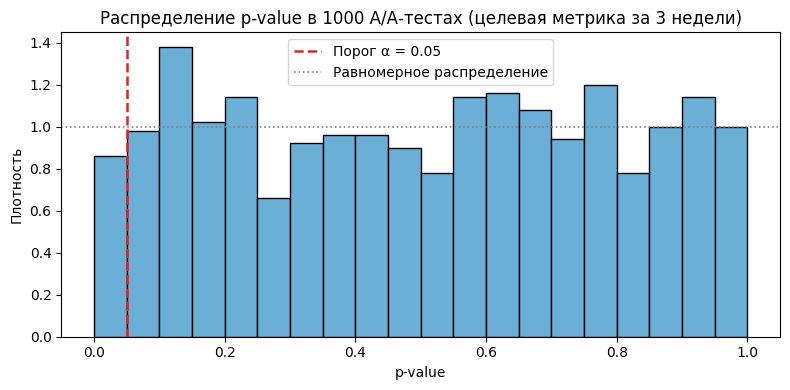

In [25]:
#
plt.figure(figsize=(8, 4))
plt.hist(p_values, bins=20, range=(0, 1), color="#6BAED6", edgecolor="black", density=True)
plt.axvline(0.05, color="#D62728", ls="--", lw=1.8, label="Порог α = 0.05")
plt.axhline(1.0, color="gray", ls=":", lw=1.2, label="Равномерное распределение")
plt.title("Распределение p-value в 1000 А/А-тестах (целевая метрика за 3 недели)")
plt.xlabel("p-value")
plt.ylabel("Плотность")
plt.legend()
plt.tight_layout()
plt.show()

**Вывод по А/А-тесту:**
* **Калибровка ошибки 1 рода:** из 1000 случайных разбиений $p < 0.05$ получили в **4.3%**, что укладывается в ожидаемый интервал при $\alpha = 0.05$ ($50 \pm 14$ ложных прокрасов), а гистограмма $p$-value имеет почти ровную форму на $[0, 1]$, а значит, распределение целевой метрики с учётом выбросов не ломает $t$-тест Уэлча, и критерий можно спокойноа использовать в эксперименте
* **Проверка SRM:** для контрольного разбиения получено $n_{\text{ctrl}} = 99\,372$, $n_{\text{test}} = 98\,517$, статистика $\chi^2 = 3.69$, $p = 0.055 \ge 0.001$ — перекоса в соотношении групп не наблюдаю